# Drift and Shift-to-Shift Variation Analysis

This notebook investigates why long-term observed variation can exceed shift-bounded short-term variation in the synthetic **BOOTH_01 / A-L1 / Coating Thickness** stream. It is a descriptive, exploratory Phase I analysis, not a causal conclusion or a confirmation of drift.

The analysis retains every measurement, including SPC-signal-bearing observations. It reuses existing SPC flags and does not read `fact_process_event`. An actual `shift_instance` is a concrete scheduled shift, including an overnight shift anchored to its scheduled 22:00 start; it is not merely a recurring shift type.

In [ ]:
from io import StringIO
from pathlib import Path
import importlib.util
import os
import subprocess
import sys


def find_repository_root(notebook_working_directory: Path) -> Path:
    """Find the repository by walking upward from the notebook working directory."""
    for candidate in (notebook_working_directory, *notebook_working_directory.parents):
        if (candidate / 'sql' / 'views.sql').is_file() and (candidate / 'src').is_dir():
            return candidate
    raise RuntimeError(
        'Repository root not found. Start the notebook from this repository or its notebooks directory.'
    )


REPO_ROOT = find_repository_root(Path.cwd().resolve())
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
database_name = os.environ.get('PGDATABASE', 'spc_quality_monitoring')
# Standard Windows pgpass location; only the path is set, the file is never read here.
if 'PGPASSFILE' not in os.environ and os.environ.get('APPDATA'):
    os.environ['PGPASSFILE'] = str(Path(os.environ['APPDATA']) / 'postgresql' / 'pgpass.conf')
# pgpass entries are matched by user; without this psql would use the OS account name.
os.environ.setdefault('PGUSER', 'postgres')

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.capability import calculate_capability
from src.drift_shift_analysis import (
    calculate_rolling_shift_instance_means,
    calculate_trend_diagnostics,
    calculate_variation_decomposition,
    first_half_second_half_comparison,
    summarize_drift_shift_inputs,
)

Protected SPC artifact check finished.


## SQL input validation

The input is the additive `v_drift_shift_measurements_booth01_a_l1` contract, sourced from the validated capability view. The SQL validation script checks measurement grain, expected reconciliation totals, rates, concrete-shift mapping, and overnight boundaries before any Python interpretation.

In [14]:
PSQL_TIMEOUT_SECONDS = 120
LIVE_ANALYSIS_AVAILABLE = False
LIVE_ANALYSIS_REASON = None
measurements = None


class PostgresUnavailable(Exception):
    """psql is missing, timed out, or could not connect/authenticate non-interactively."""


def run_psql(args):
    # -w: never prompt; credentials come only from the inherited PG* environment / PGPASSFILE.
    base = ['psql', '-X', '-w', '-v', 'ON_ERROR_STOP=1', '-d', database_name]
    env = os.environ.copy()
    env.setdefault('PGCONNECT_TIMEOUT', '10')
    try:
        result = subprocess.run(
            base + args, cwd=REPO_ROOT, capture_output=True, text=True,
            timeout=PSQL_TIMEOUT_SECONDS, env=env, stdin=subprocess.DEVNULL,
        )
    except FileNotFoundError as error:
        raise PostgresUnavailable('psql was not found on PATH.') from error
    except subprocess.TimeoutExpired as error:
        raise PostgresUnavailable(f'psql exceeded {PSQL_TIMEOUT_SECONDS}s and was stopped.') from error
    if result.returncode == 2:  # psql exit status 2 = connection/authentication failure
        lines = result.stderr.strip().splitlines()
        raise PostgresUnavailable(lines[-1] if lines else 'psql could not connect.')
    if result.returncode != 0:
        raise RuntimeError('psql query/script failed:\n' + result.stderr.strip())
    return result


try:
    sql_validation = run_psql(['-qAt', '-f', str(REPO_ROOT / 'sql' / 'analysis' / 'validate_drift_shift_analysis.sql')])
    assert not sql_validation.stdout.strip(), sql_validation.stdout
    query = (REPO_ROOT / 'sql' / 'analysis' / 'drift_shift_inputs.sql').read_text(encoding='utf-8')
    extract = run_psql(['--csv', '-c', query])
except PostgresUnavailable as error:
    LIVE_ANALYSIS_REASON = str(error)
    print('LIVE ANALYSIS NOT EXECUTED: authenticated PostgreSQL access is unavailable.')
    print(f'Reason: {LIVE_ANALYSIS_REASON}')
    print('Supply credentials outside the notebook (PGPASSWORD or pgpass.conf) and rerun. No results are shown.')
else:
    # psql --csv renders booleans as t/f; parse them as real booleans.
    measurements = pd.read_csv(StringIO(extract.stdout), true_values=['t'], false_values=['f'])
    for column in ('measurement_timestamp', 'production_timestamp', 'production_month', 'shift_instance'):
        measurements[column] = pd.to_datetime(measurements[column])
    assert len(measurements) == 4650
    assert measurements['measurement_id'].is_unique
    assert measurements['shift_instance'].nunique() == 465
    assert measurements.groupby('shift_instance').size().eq(10).all()
    assert int(measurements['is_oos'].sum()) == 56
    assert int(measurements['spc_signal'].sum()) == 174
    LIVE_ANALYSIS_AVAILABLE = True
    LIVE_ANALYSIS_REASON = None
    print('Loaded and validated 4,650 canonical measurements.')

Loaded and validated 4,650 canonical measurements.


## Monthly, actual shift-instance, and shift-type summaries

These summaries are descriptive. Rates retain their own measurement denominators; they are not subgroup capability indices.

In [15]:
if not LIVE_ANALYSIS_AVAILABLE:
    print('LIVE ANALYSIS NOT EXECUTED: skipping summaries.')
else:
    summaries = summarize_drift_shift_inputs(measurements)
    monthly = summaries['monthly'].copy()
    # Newer pandas yields 1-tuple keys for single-column groupby; unwrap so the column is a datetime.
    monthly['production_month'] = pd.to_datetime(
        monthly['production_month'].map(lambda key: key[0] if isinstance(key, tuple) else key)
    )
    shift_instances = summaries['shift_instance']
    shift_types = summaries['shift_type']

    assert monthly['measurement_count'].sum() == 4650
    assert shift_instances['measurement_count'].sum() == 4650
    assert shift_types['measurement_count'].sum() == 4650
    assert monthly['oos_count'].sum() == shift_instances['oos_count'].sum() == shift_types['oos_count'].sum() == 56
    assert monthly['spc_signal_count'].sum() == shift_instances['spc_signal_count'].sum() == shift_types['spc_signal_count'].sum() == 174
    display(monthly)
    display(shift_instances.head())
    display(shift_types)

,production_month,measurement_count,mean,sample_std,mean_deviation_from_target,below_lsl_count,above_usl_count,oos_count,oos_rate,spc_signal_count,spc_signal_rate,rule_1_count,rule_2_count,rule_3_count,rule_4_count
0,2026-01-01,805,74.573861,1.237812,-0.426139,0,0,0,0.000000,6,0.007453,0,5,1,0
1,2026-02-01,720,75.114269,1.491261,0.114269,0,0,0,0.000000,51,0.070833,4,17,34,17
2,2026-03-01,780,74.721592,1.176330,-0.278408,0,0,0,0.000000,2,0.002564,0,0,0,2
3,2026-04-01,780,74.581787,2.177128,-0.418213,18,19,37,0.047436,82,0.105128,53,35,8,2
4,2026-05-01,785,74.578801,1.245130,-0.421199,0,0,0,0.000000,2,0.002548,0,1,0,1
5,2026-06-01,775,74.844925,1.650073,-0.155075,1,18,19,0.024516,31,0.040000,26,20,14,10
6,2026-07-01,5,75.038200,1.288855,0.038200,0,0,0,0.000000,0,0.000000,0,0,0,0


,shift_instance,shift_id,shift_name,measurement_count,mean,sample_std,mean_deviation_from_target,below_lsl_count,above_usl_count,oos_count,oos_rate,spc_signal_count,spc_signal_rate,rule_1_count,rule_2_count,rule_3_count,rule_4_count,first_measurement_timestamp,last_measurement_timestamp,within_sum_of_squares
0,2026-01-01 06:00:00,1,SHIFT_01,10,74.2858,0.947441,-0.7142,0,0,0,0.0,0,0.0,0,0,0,0,2026-01-01 06:12:16.437363,2026-01-01 09:47:57.023156,8.078802
1,2026-01-01 14:00:00,2,SHIFT_02,10,74.9278,1.374481,-0.0722,0,0,0,0.0,0,0.0,0,0,0,0,2026-01-01 14:12:15.485264,2026-01-01 17:48:10.982937,17.002784
2,2026-01-01 22:00:00,3,SHIFT_03,10,74.2603,1.263827,-0.7397,0,0,0,0.0,0,0.0,0,0,0,0,2026-01-01 22:11:56.229115,2026-01-02 01:47:38.385149,14.375336
3,2026-01-02 06:00:00,1,SHIFT_01,10,74.2513,1.680354,-0.7487,0,0,0,0.0,0,0.0,0,0,0,0,2026-01-02 06:12:10.104178,2026-01-02 09:47:56.203043,25.412320
4,2026-01-02 14:00:00,2,SHIFT_02,10,74.5186,1.315291,-0.4814,0,0,0,0.0,0,0.0,0,0,0,0,2026-01-02 14:12:09.858812,2026-01-02 17:48:00.062687,15.569912


,shift_id,shift_name,measurement_count,mean,sample_std,mean_deviation_from_target,below_lsl_count,above_usl_count,oos_count,oos_rate,spc_signal_count,spc_signal_rate,rule_1_count,rule_2_count,rule_3_count,rule_4_count,shift_instance_count
0,1,SHIFT_01,1550,74.702460,1.552530,-0.297540,4,17,21,0.013548,54,0.034839,28,24,18,13,155
1,2,SHIFT_02,1550,74.788014,1.590524,-0.211986,9,11,20,0.012903,59,0.038065,32,32,20,10,155
2,3,SHIFT_03,1550,74.700001,1.490756,-0.299999,6,9,15,0.009677,61,0.039355,23,22,19,9,155


## Time-series and SPC overlay

Signals are plotted only as supplied investigation prompts. Neither the points nor the trend calculations are filtered by signal status.

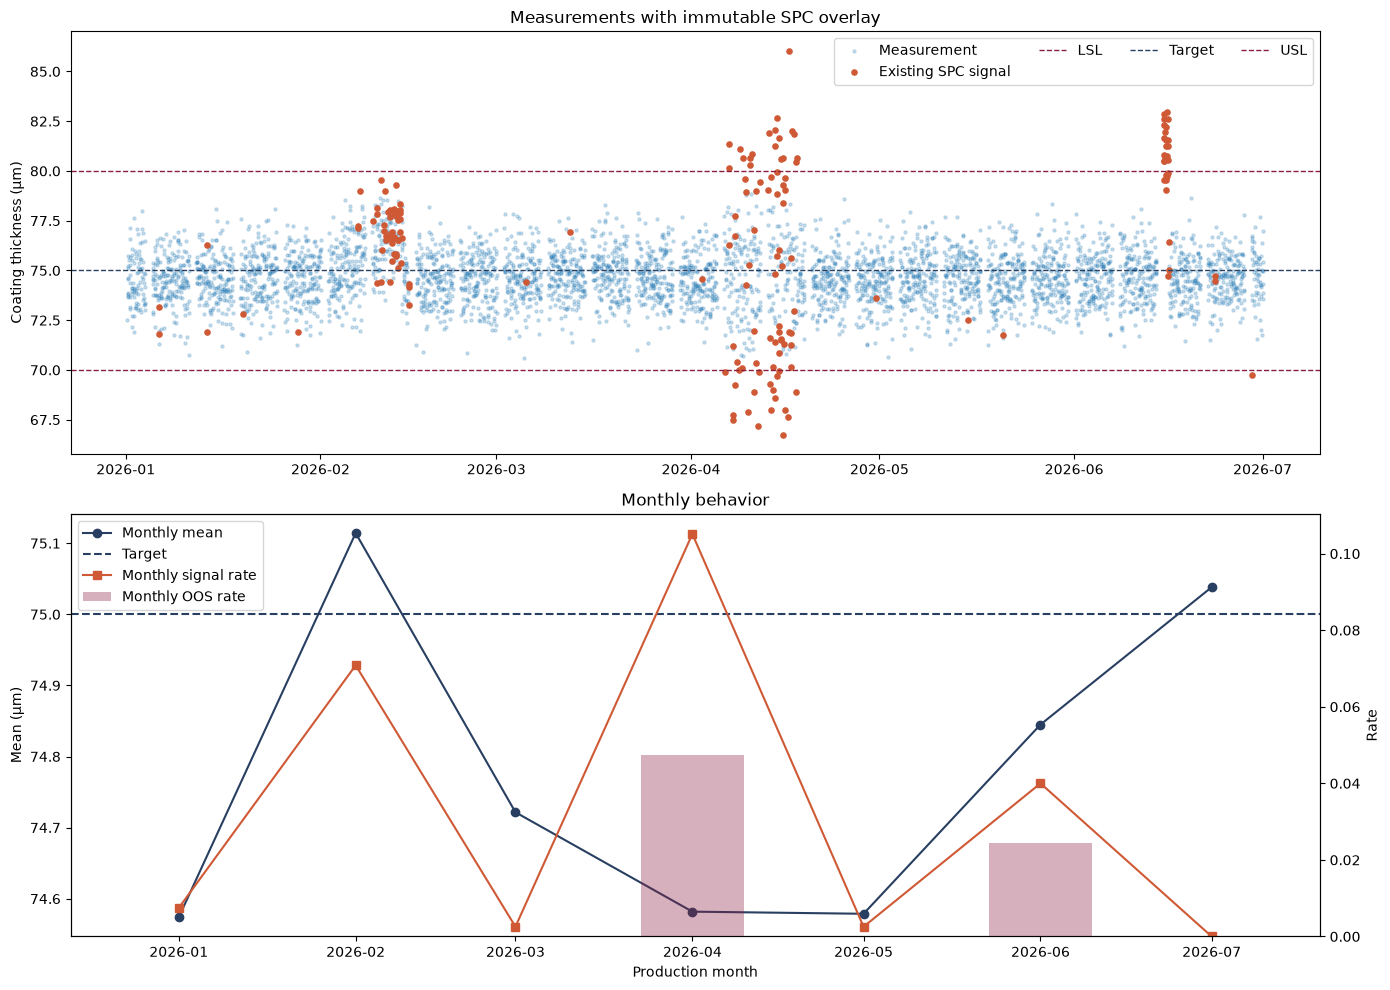

In [20]:
if not LIVE_ANALYSIS_AVAILABLE:
    print('LIVE ANALYSIS NOT EXECUTED: skipping plots.')
else:
    figure, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=False)
    axes[0].scatter(measurements['measurement_timestamp'], measurements['measured_value'], s=5, alpha=0.22, label='Measurement')
    signal_rows = measurements[measurements['spc_signal'].astype(bool)]
    axes[0].scatter(signal_rows['measurement_timestamp'], signal_rows['measured_value'], s=14, color='#cf5935', label='Existing SPC signal')
    for value, label, color in [(70, 'LSL', '#8b1e3f'), (75, 'Target', '#283f61'), (80, 'USL', '#8b1e3f')]:
        axes[0].axhline(value, color=color, linestyle='--', linewidth=1, label=label)
    axes[0].set(title='Measurements with immutable SPC overlay', ylabel='Coating thickness (µm)')
    axes[0].legend(ncol=4)
    # Rates (0-1) and means (~75 µm) need separate y-axes to both be visible.
    axes[1].plot(monthly['production_month'], monthly['mean'], marker='o', color='#283f61', label='Monthly mean')
    axes[1].axhline(75, color='#283f61', linestyle='--', label='Target')
    axes[1].set(title='Monthly behavior', ylabel='Mean (µm)', xlabel='Production month')
    rate_axis = axes[1].twinx()
    rate_axis.bar(monthly['production_month'], monthly['oos_rate'], alpha=.35, width=18, color='#8b1e3f', label='Monthly OOS rate')
    rate_axis.plot(monthly['production_month'], monthly['spc_signal_rate'], marker='s', color='#cf5935', label='Monthly signal rate')
    rate_axis.set_ylabel('Rate')
    handles = axes[1].get_legend_handles_labels()[0] + rate_axis.get_legend_handles_labels()[0]
    labels = axes[1].get_legend_handles_labels()[1] + rate_axis.get_legend_handles_labels()[1]
    axes[1].legend(handles, labels, loc='upper left')
    figure.tight_layout()
    plt.show()

## Rolling means, OLS trend, and first-half/second-half comparison

Actual shift-instance means are the primary time unit. The reported 95% confidence interval is normal-approximation and is not autocorrelation-adjusted. The diagnostic is observational and does not by itself establish physical drift.

,trend_unit,observation_count,time_origin,duration_days,slope_per_day,slope_standard_error,slope_ci_95_low,slope_ci_95_high,confidence_interval_method,estimated_cumulative_fitted_change,fitted_values,residuals,leave_one_shift_out_slope_min,leave_one_shift_out_slope_max,max_leave_one_shift_out_slope_change,slope_direction_stable_under_leave_one_out,observational_caveat
0,actual_shift_instance_mean,465,2026-01-01 06:00:00,180.666667,-0.000424,0.000624,-0.001648,0.0008,normal_approximation_95_percent,-0.076624,"[74.76843449580268, 74.7682931230998, 74.76815...","[-0.48263449580268514, 0.1595068769002097, -0....",-0.000818,-0.000337,0.000394,True,Trend diagnostics describe association with ti...


,first_half_shift_instance_count,second_half_shift_instance_count,first_half_mean,second_half_mean,second_minus_first_mean,first_half_sample_std,second_half_sample_std,first_half_start,first_half_end,second_half_start,second_half_end
0,232,233,74.791543,74.669037,-0.122506,0.634448,0.760667,2026-01-01 06:00:00,2026-04-01 06:00:00,2026-04-01 14:00:00,2026-06-30 22:00:00


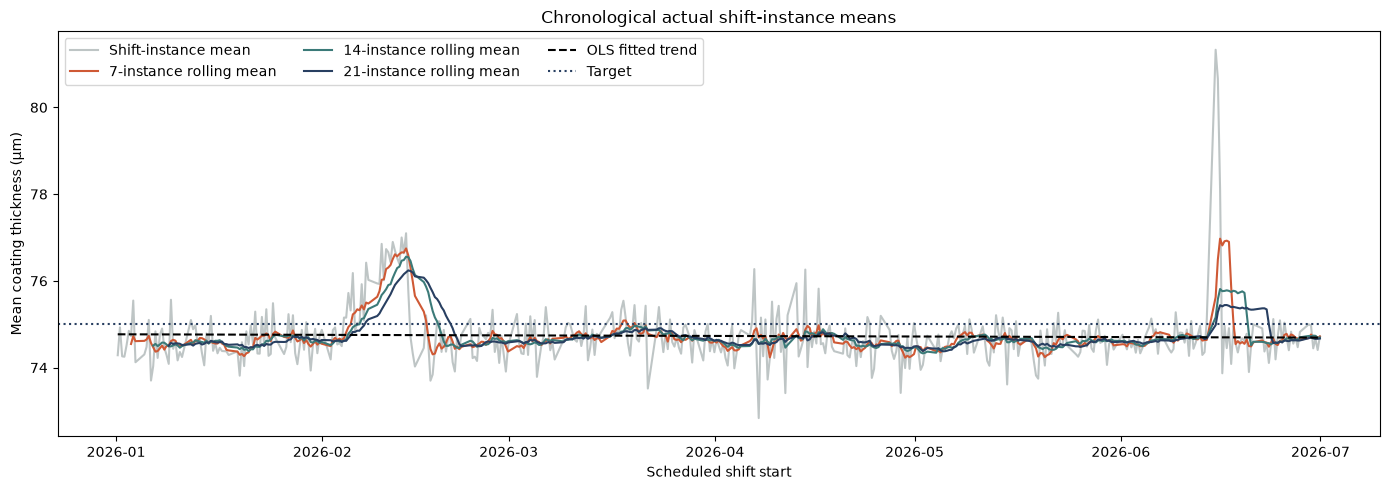

In [17]:
if not LIVE_ANALYSIS_AVAILABLE:
    print('LIVE ANALYSIS NOT EXECUTED: skipping rolling means, trend and half comparison.')
else:
    rolling = calculate_rolling_shift_instance_means(shift_instances, windows=(7, 14, 21))
    trend = calculate_trend_diagnostics(shift_instances)
    halves = first_half_second_half_comparison(shift_instances)
    display(pd.DataFrame([trend]))
    display(pd.DataFrame([halves]))

    figure, axis = plt.subplots(figsize=(14, 5))
    axis.plot(rolling['shift_instance'], rolling['mean'], color='#7f8c8d', alpha=.5, label='Shift-instance mean')
    for window, color in [(7, '#cf5935'), (14, '#3b7a78'), (21, '#283f61')]:
        axis.plot(rolling['shift_instance'], rolling[f'rolling_mean_{window}'], color=color, label=f'{window}-instance rolling mean')
    elapsed_days = (rolling['shift_instance'] - rolling['shift_instance'].iloc[0]).dt.total_seconds() / 86400
    fitted = rolling['mean'].mean() + trend['slope_per_day'] * (elapsed_days - elapsed_days.mean())
    axis.plot(rolling['shift_instance'], fitted, color='black', linestyle='--', label='OLS fitted trend')
    axis.axhline(75, color='#283f61', linestyle=':', label='Target')
    axis.set(title='Chronological actual shift-instance means', ylabel='Mean coating thickness (µm)', xlabel='Scheduled shift start')
    axis.legend(ncol=3)
    figure.tight_layout()
    plt.show()

## Variation decomposition

The one-way shift-instance identity is `Total SS = Within-shift SS + Between-shift SS`. Pooled within-shift SD describes observations around their own shift means. It is not the existing I-MR within sigma, which estimates short-term variation from shift-bounded adjacent moving ranges. Overall sigma contains both types of observed variation.

,measurement_count,shift_instance_count,overall_mean,total_sum_of_squares,within_shift_sum_of_squares,between_shift_sum_of_squares,within_shift_share,between_shift_share,pooled_within_shift_sd,overall_sample_sd
0,4650,465,74.730158,11102.447049,8812.783814,2289.663235,0.793769,0.206231,1.451138,1.54536


,measurement_count,shift_instance_count
0,10,465


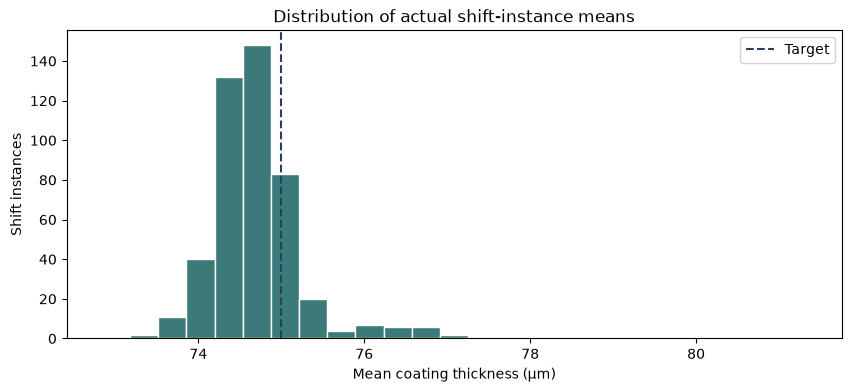

In [18]:
if not LIVE_ANALYSIS_AVAILABLE:
    print('LIVE ANALYSIS NOT EXECUTED: skipping variation decomposition.')
else:
    decomposition = calculate_variation_decomposition(measurements)
    assert np.isclose(decomposition['total_sum_of_squares'], decomposition['within_shift_sum_of_squares'] + decomposition['between_shift_sum_of_squares'])
    display(pd.DataFrame([{key: value for key, value in decomposition.items() if not isinstance(value, pd.DataFrame)}]))
    display(decomposition['subgroup_size_distribution'])

    figure, axis = plt.subplots(figsize=(10, 4))
    axis.hist(decomposition['shift_instance_mean_distribution']['mean'], bins=25, color='#3b7a78', edgecolor='white')
    axis.axvline(75, color='#283f61', linestyle='--', label='Target')
    axis.set(title='Distribution of actual shift-instance means', xlabel='Mean coating thickness (µm)', ylabel='Shift instances')
    axis.legend()
    plt.show()

## Connection to capability and predefined evidence framework

`Cp > Pp` and `Cpk > Ppk` are compatible with overall historical spread exceeding the I-MR short-term estimate. The decomposition and trend outputs identify the observable within-shift, between-shift, and time-associated contributions; they do not assign a physical cause.

A pattern is only *evidence consistent with sustained drift* if all predeclared conditions hold: directional slope whose uncertainty excludes zero, practically meaningful fitted change, compatible chronological-half result, compatible 7/14/21 rolling patterns, and no complete reliance on isolated shifts. Even then, report an observational pattern rather than confirmed causal drift. The practical threshold below is deliberately displayed for owner review, not treated as a universal quality standard.

In [19]:
if not LIVE_ANALYSIS_AVAILABLE:
    print('LIVE ANALYSIS NOT EXECUTED: skipping capability connection and evidence framework.')
else:
    capability = calculate_capability(measurements)
    practical_change_threshold = 0.25 * capability['within_sigma']  # owner-review threshold, not a control limit
    slope_direction = np.sign(trend['slope_per_day'])
    rolling_changes = [
        rolling[f'rolling_mean_{window}'].dropna().iloc[-1] - rolling[f'rolling_mean_{window}'].dropna().iloc[0]
        for window in (7, 14, 21)
    ]
    evidence = {
        'slope_ci_excludes_zero': trend['slope_ci_95_low'] > 0 or trend['slope_ci_95_high'] < 0,
        'practically_meaningful_candidate': abs(trend['estimated_cumulative_fitted_change']) >= practical_change_threshold,
        'half_comparison_direction_compatible': np.sign(halves['second_minus_first_mean']) == slope_direction and slope_direction != 0,
        'rolling_direction_compatible': all(np.sign(change) == slope_direction and slope_direction != 0 for change in rolling_changes),
        'leave_one_out_direction_stable': trend['slope_direction_stable_under_leave_one_out'],
        'status': 'Evidence consistent with sustained drift (observational, not causal)'
            if all([trend['slope_ci_95_low'] > 0 or trend['slope_ci_95_high'] < 0, abs(trend['estimated_cumulative_fitted_change']) >= practical_change_threshold, np.sign(halves['second_minus_first_mean']) == slope_direction and slope_direction != 0, all(np.sign(change) == slope_direction and slope_direction != 0 for change in rolling_changes), trend['slope_direction_stable_under_leave_one_out']])
            else 'Insufficient evidence to describe sustained drift under the predefined framework',
    }
    display(pd.DataFrame([evidence]))
    print({key: capability[key] for key in ('within_sigma', 'overall_sigma', 'Cp', 'Cpk', 'Pp', 'Ppk')})

,slope_ci_excludes_zero,practically_meaningful_candidate,half_comparison_direction_compatible,rolling_direction_compatible,leave_one_out_direction_stable,status
0,False,False,True,False,True,Insufficient evidence to describe sustained dr...


{'within_sigma': 1.3842670971131281, 'overall_sigma': 1.545359698910062, 'Cp': 1.2040065606865027, 'Cpk': 1.1390282685523185, 'Pp': 1.0784975613393841, 'Ppk': 1.0202927874660939}


## Statistical limitations and deterministic validation report

Autocorrelation may make independent-observation uncertainty optimistic. Shift type may be confounded with time or unmeasured conditions. Multiple descriptive comparisons can surface chance patterns. The data are synthetic and deliberately patterned, so results demonstrate a reproducible method rather than real paintshop performance. SPC signals remain investigation prompts, not confirmed special causes.

In [ ]:
def run_optional(command, timeout=300):
    """Run a non-fatal check; report the limitation instead of failing Run All."""
    try:
        return subprocess.run(command, cwd=REPO_ROOT, capture_output=True, text=True, timeout=timeout, stdin=subprocess.DEVNULL)
    except (FileNotFoundError, subprocess.TimeoutExpired) as error:
        print(f'Could not run {" ".join(command[:3])}: {error}')
        return None


print('Live data status:', 'LIVE ANALYSIS EXECUTED' if LIVE_ANALYSIS_AVAILABLE else f'LIVE ANALYSIS NOT EXECUTED ({LIVE_ANALYSIS_REASON})')

for protected_path in ('sql/analysis/spc_rules.sql', 'sql/analysis/spc_signal_summary.sql'):
    protected = run_optional(['git', 'diff', '--quiet', 'HEAD', '--', protected_path], timeout=60)
    if protected is not None:
        assert protected.returncode == 0, f'Protected SPC artifact changed: {protected_path}'
        print(f'{protected_path}: matches HEAD')

if importlib.util.find_spec('pytest') is not None:
    tests = run_optional([sys.executable, '-m', 'pytest', 'tests/test_drift_shift_analysis.py', 'tests/test_capability.py', '-q'])
    if tests is not None:
        print(tests.stdout.strip() or tests.stderr.strip())
        print('pytest:', 'PASS' if tests.returncode == 0 else f'FAIL (exit {tests.returncode})')
else:
    print('pytest is not installed in this kernel; test suite not executed.')

diff_check = run_optional(['git', 'diff', '--check'], timeout=60)
if diff_check is not None:
    print('git diff --check:', 'clean' if diff_check.returncode == 0 and not diff_check.stdout.strip() else 'reported issues (non-fatal)')
    if diff_check.stdout.strip():
        print(diff_check.stdout.strip())

if LIVE_ANALYSIS_AVAILABLE:
    print('SQL validation: PASS (data-load cell completed without raising)')
    print('No SPC signals were removed; no event data was read.')
else:
    print('SQL validation and all data-dependent results were not produced; nothing above should be read as a pass.')

.........................                                                [100%]
25 passed in 1.42s
pytest: PASS
git diff --check: clean
SQL validation: PASS (earlier cell completed without raising)
LIVE ANALYSIS EXECUTED
No SPC signals were removed; no event data was read.
